### Folgen und Reihen: Rekursion, Konvergenz, Reihen, Taylorpolynome - Übungen

In diesem Notebook (Vertiefungskurs) geht es um **Folgen und Reihen**: explizite und rekursive Folgen, Monotonie und Beschränktheit,
**Grenzwerte** und die genaue Definition der **Konvergenz**, unendliche **Reihen** wie die geometrische und die harmonische Reihe
und (als Zusatz) **Taylorpolynome**, mit denen man Funktionen durch Polynome annähert.

Vorausgesetzt werden die Notebooks *Logik und Beweise* (Summen, Induktion) und *Ableitungsregeln* (`limit`).

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die natürlichen Zahlen `n`, `k`, die reelle Variable `x` und das Funktionssymbol `f` (für rekursive Folgen) an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
n, k = symbols('n k', integer=True, positive=True)
x = symbols('x', real=True)
f = Function('f')

## 1. Folgen

#### Explizite Folgen

Eine **Folge** (aₙ) ordnet jeder natürlichen Zahl n eine Zahl aₙ zu, z. B. aₙ = 1/n: 1, 1/2, 1/3, ...
Bei einer **expliziten** Folge steht aₙ als Term in n da.

- `a = sequence(term, (n, 1, oo))` legt die Folge an, `a[:5]` gibt die ersten 5 Glieder.
- Ebenso geht `[term.subs(n, i) for i in range(1, 6)]`.
- **Arithmetische Folge:** konstante Differenz d, aₙ = a₁ + (n − 1)·d. **Geometrische Folge:** konstanter Quotient q, aₙ = a₁ · qⁿ⁻¹.

In [ ]:
a = sequence(1 / n, (n, 1, oo))
display(a)
display(a[:5])
an = (2*n - 1) / (n + 1)
werte = [an.subs(n, i) for i in range(1, 11)]
display(werte)
plt.plot(range(1, 11), [N(w) for w in werte], 'o')
plt.show()

#### Aufgabe 1.1

Gib die ersten 6 Glieder der Folge aₙ = n²/(n + 1) aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{1}{2}, \  \frac{4}{3}, \  \frac{9}{4}, \  \frac{16}{5}, \  \frac{25}{6}, \  \frac{36}{7}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
sequence(n**2 / (n + 1), (n, 1, oo))[:6]
```

</details>

#### Aufgabe 1.2

Gib die ersten 6 Glieder der Folge aₙ = (−1)ⁿ / n aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ -1, \  \frac{1}{2}, \  - \frac{1}{3}, \  \frac{1}{4}, \  - \frac{1}{5}, \  \frac{1}{6}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
sequence((-1)**n / n, (n, 1, oo))[:6]
```

</details>

#### Aufgabe 1.3

Gib die ersten 6 Glieder der arithmetischen Folge mit a₁ = 7 und d = −3 aus und das 100. Glied.

**Erwartete Ausgabe:**

$\displaystyle \left[ 7, \  4, \  1, \  -2, \  -5, \  -8\right]$

$\displaystyle -290$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = 7 + (n - 1) * (-3)
display([an.subs(n, i) for i in range(1, 7)])
an.subs(n, 100)
```

</details>

#### Aufgabe 1.4

Gib die ersten 6 Glieder der geometrischen Folge mit a₁ = 3 und q = 1/2 aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 3, \  \frac{3}{2}, \  \frac{3}{4}, \  \frac{3}{8}, \  \frac{3}{16}, \  \frac{3}{32}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = 3 * Rational(1, 2)**(n - 1)
[an.subs(n, i) for i in range(1, 7)]
```

</details>

#### Aufgabe 1.5

Eine geometrische Folge hat a₁ = 2 und a₄ = 54. Bestimme q (reell) und den expliziten Term.

**Erwartete Ausgabe:**

$\displaystyle \left[ 3\right]$

$\displaystyle 2 \cdot 3^{n - 1}$

In [ ]:
q = symbols('q', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
q = symbols('q', real=True)
qs = solve(Eq(2 * q**3, 54), q)
display(qs)
2 * qs[0]**(n - 1)
```

</details>

#### Aufgabe 1.6

Ab welchem n ist das Glied der Folge aₙ = 1,05ⁿ größer als 100? (Schleife)

**Erwartete Ausgabe:**

$\displaystyle 95$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = 1
while Rational(105, 100)**m <= 100:
    m += 1
m
```

</details>

#### Aufgabe 1.7

Zeichne die ersten 20 Glieder der Folge aₙ = (−1)ⁿ / n als Punkte.

**Erwartete Ausgabe:**



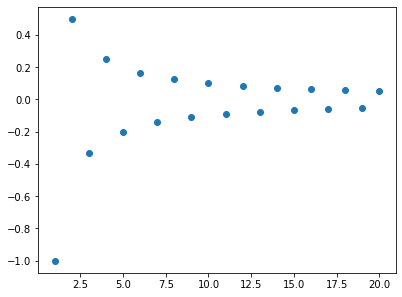

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = (-1)**n / n
plt.plot(range(1, 21), [N(an.subs(n, i)) for i in range(1, 21)], 'o')
plt.show()
```

</details>

#### Aufgabe 1.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
a = sequence(2**n, (n, 1, oo))
display(a[:4])
display(sequence(3*n - 1, (n, 0, oo))[:4])
sequence(Rational(1, 2)**n, (n, 0, oo))[:3]
```

In [ ]:
a = sequence(2**n, (n, 1, oo))
display(a[:4])
display(sequence(3*n - 1, (n, 0, oo))[:4])
sequence(Rational(1, 2)**n, (n, 0, oo))[:3]

## 2. Rekursive Folgen

#### Jedes Glied aus dem vorigen

Bei einer **rekursiven** Folge ist ein Anfangswert gegeben und eine Regel, wie man aus aₙ das nächste Glied aₙ₊₁ berechnet,
z. B. a₁ = 3, aₙ₊₁ = 2·aₙ. Die Glieder berechnet man mit einer Schleife.

`rsolve(gleichung, f(n), {f(1): 3})` sucht einen **expliziten** Term (mit dem Funktionssymbol f): Die Rekursion wird als
Ausdruck geschrieben, der null sein soll, z. B. f(n + 1) − 2·f(n).

In [ ]:
folge = [3]
for i in range(5):
    folge.append(2 * folge[-1])
display(folge)
display(rsolve(f(n + 1) - 2 * f(n), f(n), {f(1): 3}))
rsolve(f(n + 1) - f(n) - 3, f(n), {f(0): 2})

#### Aufgabe 2.1

Berechne die ersten 8 Glieder der Folge a₁ = 1, aₙ₊₁ = 3·aₙ − 1 mit einer Schleife.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  2, \  5, \  14, \  41, \  122, \  365, \  1094\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
folge = [1]
for i in range(7):
    folge.append(3 * folge[-1] - 1)
folge
```

</details>

#### Aufgabe 2.2

Bestimme mit `rsolve` den expliziten Term der Folge aus der vorigen Aufgabe und prüfe ihn für n = 1 bis 5.

**Erwartete Ausgabe:**

$\displaystyle \frac{3^{n}}{6} + \frac{1}{2}$

$\displaystyle \left[ 1, \  2, \  5, \  14, \  41\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = rsolve(f(n + 1) - 3 * f(n) + 1, f(n), {f(1): 1})
display(an)
[an.subs(n, i) for i in range(1, 6)]
```

</details>

#### Aufgabe 2.3

Die **Fibonacci-Folge**: f₀ = 0, f₁ = 1, fₙ₊₂ = fₙ₊₁ + fₙ. Berechne die ersten 15 Glieder mit einer Schleife und vergleiche mit `fibonacci(i)`.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  1, \  1, \  2, \  3, \  5, \  8, \  13, \  21, \  34, \  55, \  89, \  144, \  233, \  377\right]$

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
folge = [0, 1]
for i in range(13):
    folge.append(folge[-1] + folge[-2])
display(folge)
folge == [fibonacci(i) for i in range(15)]
```

</details>

#### Aufgabe 2.4

Bestimme mit `rsolve` den expliziten Term der Fibonacci-Folge (Formel von Binet).

**Erwartete Ausgabe:**

$\displaystyle - \frac{\sqrt{5} \left(\frac{1}{2} - \frac{\sqrt{5}}{2}\right)^{n}}{5} + \frac{\sqrt{5} \left(\frac{1}{2} + \frac{\sqrt{5}}{2}\right)^{n}}{5}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
rsolve(f(n + 2) - f(n + 1) - f(n), f(n), {f(0): 0, f(1): 1})
```

</details>

#### Aufgabe 2.5

Die Quotienten fₙ₊₁/fₙ aufeinanderfolgender Fibonacci-Zahlen nähern sich dem **goldenen Schnitt**. Gib die Quotienten für n = 10, 20, 30 mit 10 Ziffern aus
und den goldenen Schnitt (1 + √5)/2 mit 10 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1.618181818, \  1.618033999, \  1.618033989\right]$

$\displaystyle 1.618033989$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display([N(Rational(fibonacci(i + 1), fibonacci(i)), 10) for i in [10, 20, 30]])
N((1 + sqrt(5)) / 2, 10)
```

</details>

#### Aufgabe 2.6

**Medikament:** Jeden Tag werden 3 mg eingenommen, über Nacht werden 50 % abgebaut: a₀ = 0, aₙ₊₁ = 0,5·aₙ + 3. Gib den expliziten Term (`rsolve`) und den Grenzwert für n → ∞ aus.

**Erwartete Ausgabe:**

$\displaystyle 6 - 6 \cdot 2^{- n}$

$\displaystyle 6$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = rsolve(f(n + 1) - Rational(1, 2) * f(n) - 3, f(n), {f(0): 0})
display(an)
limit(an, n, oo)
```

</details>

#### Aufgabe 2.7

**Heron-Verfahren:** Die Folge x₁ = 1, xₙ₊₁ = (xₙ + 2/xₙ)/2 nähert √2 an. Berechne x₁ bis x₅ genau (als Brüche) und x₅ − √2 mit 3 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  \frac{3}{2}, \  \frac{17}{12}, \  \frac{577}{408}, \  \frac{665857}{470832}\right]$

$\displaystyle 1.59 \cdot 10^{-12}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
folge = [Integer(1)]
for i in range(4):
    folge.append((folge[-1] + 2 / folge[-1]) / 2)
display(folge)
N(folge[-1] - sqrt(2), 3)
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
folge = [1]
for i in range(4):
    folge.append(folge[-1] + 2)
folge
```

In [ ]:
folge = [1]
for i in range(4):
    folge.append(folge[-1] + 2)
folge

## 3. Monotonie und Beschränktheit

#### Steigt die Folge?

Eine Folge ist **streng monoton steigend**, wenn aₙ₊₁ − aₙ > 0 für alle n, **fallend**, wenn aₙ₊₁ − aₙ < 0. Man berechnet die Differenz
allgemein und vereinfacht sie (`factor`/`simplify`), bis man das Vorzeichen sieht. Bei positiven Gliedern kann man auch den Quotienten
aₙ₊₁/aₙ mit 1 vergleichen.

Eine Folge ist **beschränkt**, wenn es Zahlen S und s gibt mit s ≤ aₙ ≤ S für alle n.

In [ ]:
an = (2*n - 1) / (n + 1)
d = factor(an.subs(n, n + 1) - an)
display(d)
display(d > 0)
display(simplify(an - 2))

#### Aufgabe 3.1

Untersuche die Monotonie von aₙ = (3n + 2)/(n + 1): Gib aₙ₊₁ − aₙ faktorisiert aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{\left(n + 1\right) \left(n + 2\right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = (3*n + 2) / (n + 1)
factor(an.subs(n, n + 1) - an)
```

</details>

#### Aufgabe 3.2

Untersuche die Monotonie von aₙ = n/2ⁿ: Gib den Quotienten aₙ₊₁/aₙ vereinfacht aus und für welche n er kleiner als 1 ist (Liste für n = 1 bis 5).

**Erwartete Ausgabe:**

$\displaystyle \frac{n + 1}{2 n}$

$\displaystyle \left[ \text{False}, \  \text{True}, \  \text{True}, \  \text{True}, \  \text{True}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = n / 2**n
qu = simplify(an.subs(n, n + 1) / an)
display(qu)
[qu.subs(n, i) < 1 for i in range(1, 6)]
```

</details>

#### Aufgabe 3.3

Zeige, dass aₙ = (3n + 2)/(n + 1) durch 3 nach oben beschränkt ist: Gib 3 − aₙ vereinfacht aus (positiv für alle n).

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{n + 1}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
simplify(3 - (3*n + 2) / (n + 1))
```

</details>

#### Aufgabe 3.4

Untersuche die Monotonie von aₙ = n² − 6n: Gib aₙ₊₁ − aₙ aus und ab welchem n die Folge steigt (`solveset` über `Interval(1, oo)`).

**Erwartete Ausgabe:**

$\displaystyle 2 n - 5$

$\displaystyle \left(\frac{5}{2}, \infty\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
d = expand((n + 1)**2 - 6*(n + 1) - (n**2 - 6*n))
display(d)
nr = symbols('nr', real=True)
solveset(d.subs(n, nr) > 0, nr, Interval(1, oo))
```

</details>

#### Aufgabe 3.5

Ist die Folge aₙ = (1 + 1/n)ⁿ monoton steigend? Gib die ersten 6 Glieder mit 5 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 2.0, \  2.25, \  2.3704, \  2.4414, \  2.4883, \  2.5216\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
an = (1 + 1/n)**n
[N(an.subs(n, i), 5) for i in range(1, 7)]
```

</details>

## 4. Grenzwert und Konvergenz

#### Die ε-Definition

Eine Folge (aₙ) **konvergiert** gegen den Grenzwert g, wenn für **jedes** ε > 0 ab einem Index n₀ alle Glieder im Streifen
g − ε < aₙ < g + ε liegen, also |aₙ − g| < ε für alle n ≥ n₀. Eine Folge ohne Grenzwert heißt **divergent**.

- `limit(an, n, oo)` berechnet den Grenzwert.
- Für ein bestimmtes ε berechnet man n₀: Löse |aₙ − g| < ε nach n (mit einer reellen Variablen `nr`). Ist die Lösung ein Intervall `l`,
  ist `l.inf` seine untere Grenze; `floor(l.inf) + 1` ist dann die kleinste ganze Zahl im Intervall (bei offenem Intervall).

**Wichtig:** `limit` kann Folgen mit (−1)ⁿ in sympy 1.14 nicht berechnen. Dann hilft der Betrag: Geht |aₙ| → 0, geht auch aₙ → 0.

In [ ]:
an = (2*n + 1) / (n + 3)
g = limit(an, n, oo)
display(g)
nr = symbols('nr', positive=True)
abstand = simplify(Abs(an.subs(n, nr) - g))
display(abstand)
display(solveset(abstand < Rational(1, 100), nr, Interval(0, oo)))
limit(1 / n, n, oo)

#### Aufgabe 4.1

Berechne die Grenzwerte von aₙ = (5n² − 1)/(2n² + n) und bₙ = (n + 1)/n².

**Erwartete Ausgabe:**

$\displaystyle \frac{5}{2}$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit((5*n**2 - 1) / (2*n**2 + n), n, oo))
limit((n + 1) / n**2, n, oo)
```

</details>

#### Aufgabe 4.2

Berechne die Grenzwerte von aₙ = √(n + 1) − √n und bₙ = n · (√(n² + 1) − n).

**Erwartete Ausgabe:**

$\displaystyle 0$

$\displaystyle \frac{1}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit(sqrt(n + 1) - sqrt(n), n, oo))
limit(n * (sqrt(n**2 + 1) - n), n, oo)
```

</details>

#### Aufgabe 4.3

Berechne den Grenzwert der Folge aₙ = (1 + 1/n)ⁿ und von bₙ = (1 + 2/n)ⁿ.

**Erwartete Ausgabe:**

$\displaystyle e$

$\displaystyle e^{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit((1 + 1/n)**n, n, oo))
limit((1 + 2/n)**n, n, oo)
```

</details>

#### Aufgabe 4.4

Berechne die Grenzwerte von aₙ = n/2ⁿ, bₙ = n^(1/n) und cₙ = sin(n)/n.

**Erwartete Ausgabe:**

$\displaystyle 0$

$\displaystyle 1$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit(n / 2**n, n, oo))
display(limit(n**(1/n), n, oo))
limit(sin(n) / n, n, oo)
```

</details>

#### Aufgabe 4.5

Für aₙ = (3n + 2)/(n + 1) mit Grenzwert 3: Ab welchem Index n₀ gilt |aₙ − 3| < 0,001? Gib die Lösungsmenge für nr und das kleinste ganze n₀ aus.

**Erwartete Ausgabe:**

$\displaystyle \left(999, \infty\right)$

$\displaystyle 1000$

In [ ]:
nr = symbols('nr', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
nr = symbols('nr', positive=True)
l = solveset(Abs((3*nr + 2) / (nr + 1) - 3) < Rational(1, 1000), nr, Interval(0, oo))
display(l)
floor(l.inf) + 1
```

</details>

#### Aufgabe 4.6

Für aₙ = 1/n²: Bestimme in Abhängigkeit von ε > 0 die Grenze, ab der 1/n² < ε gilt (löse 1/n² = ε nach nr > 0). Das zeigt: Für jedes ε gibt es ein n₀.
Gib auch die Grenze für ε = 1/10000 aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{\sqrt{\epsilon}}$

$\displaystyle 100$

In [ ]:
nr = symbols('nr', positive=True)
eps = symbols('epsilon', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
nr = symbols('nr', positive=True)
eps = symbols('epsilon', positive=True)
grenze = solve(Eq(1 / nr**2, eps), nr)[0]
display(grenze)
grenze.subs(eps, Rational(1, 10000))
```

</details>

#### Aufgabe 4.7

Die Folge aₙ = (−1)ⁿ / n: `limit` funktioniert hier nicht. Berechne stattdessen den Grenzwert von |aₙ| = 1/n.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
limit(1 / n, n, oo)
```

</details>

#### Aufgabe 4.8

Die Folge aₙ = (−1)ⁿ ist divergent: Sie hat die beiden **Häufungspunkte** −1 und 1. Gib die Grenzwerte der Teilfolgen a₂ₙ und a₂ₙ₋₁ aus (setze 2n bzw. 2n − 1 ein und vereinfache).

**Erwartete Ausgabe:**

$\displaystyle 1$

$\displaystyle -1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(simplify((-1)**(2*n)))
simplify((-1)**(2*n - 1))
```

</details>

#### Aufgabe 4.9

Gib die Grenzwerte von aₙ = 2ⁿ/n² und bₙ = n!/nⁿ aus.

**Erwartete Ausgabe:**

$\displaystyle \infty$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit(2**n / n**2, n, oo))
limit(factorial(n) / n**n, n, oo)
```

</details>

#### Aufgabe 4.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(limit(5 + 1/n, n, oo))
display(limit(n**2, n, oo))
display(limit(Rational(1, 2)**n, n, oo))
limit((n**2 + 1) / (n**2 - 1), n, oo)
```

In [ ]:
display(limit(5 + 1/n, n, oo))
display(limit(n**2, n, oo))
display(limit(Rational(1, 2)**n, n, oo))
limit((n**2 + 1) / (n**2 - 1), n, oo)

## 5. Reihen

#### Partialsummen und unendliche Summen

Eine **Reihe** ist die Folge der **Partialsummen** sₙ = a₁ + a₂ + ... + aₙ. Konvergiert sₙ, schreibt man den Grenzwert als unendliche Summe Σ aₖ.

- `summation(term, (k, 1, n))` gibt die Partialsumme allgemein, `summation(term, (k, 1, oo))` die unendliche Summe.
- `Sum(term, (k, 1, oo))` schreibt die Summe nur hin; `.doit()` rechnet, `.is_convergent()` prüft die Konvergenz.
- **Geometrische Reihe:** Σₖ₌₀^∞ qᵏ = 1/(1 − q) für |q| < 1.
- **Harmonische Reihe:** Σ 1/k divergiert, obwohl 1/k → 0 geht. Σ 1/k² konvergiert dagegen (gegen π²/6).

In [ ]:
display(summation(Rational(1, 2)**k, (k, 0, n)))
s = Sum(Rational(1, 2)**k, (k, 0, oo))
display(Eq(s, s.doit()))
display(Sum(1/k, (k, 1, oo)).is_convergent(), Sum(1/k**2, (k, 1, oo)).is_convergent())
summation(1/k**2, (k, 1, oo))

#### Aufgabe 5.1

Berechne die Summe der geometrischen Reihe Σₖ₌₀^∞ (2/3)ᵏ und Σₖ₌₁^∞ 3 · (1/4)ᵏ.

**Erwartete Ausgabe:**

$\displaystyle 3$

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(summation(Rational(2, 3)**k, (k, 0, oo)))
summation(3 * Rational(1, 4)**k, (k, 1, oo))
```

</details>

#### Aufgabe 5.2

Schreibe die periodische Dezimalzahl 0,777... als geometrische Reihe Σₖ₌₁^∞ 7 · (1/10)ᵏ und berechne sie.

**Erwartete Ausgabe:**

$\displaystyle \frac{7}{9}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
summation(7 * Rational(1, 10)**k, (k, 1, oo))
```

</details>

#### Aufgabe 5.3

**Teleskopsumme:** Zerlege 1/(k(k + 1)) mit `apart` in Partialbrüche, gib die Partialsumme bis n und die unendliche Summe aus.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{k + 1} + \frac{1}{k}$

$\displaystyle \frac{n}{n + 1}$

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(apart(1 / (k * (k + 1)), k))
display(simplify(summation(1 / (k * (k + 1)), (k, 1, n))))
summation(1 / (k * (k + 1)), (k, 1, oo))
```

</details>

#### Aufgabe 5.4

Prüfe mit `is_convergent()`, welche der Reihen Σ 1/√k, Σ 1/k³, Σ k/2ᵏ konvergieren (Liste).

**Erwartete Ausgabe:**

$\displaystyle \left[ \text{False}, \  \text{True}, \  \text{True}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[Sum(t, (k, 1, oo)).is_convergent() for t in [1 / sqrt(k), 1 / k**3, k / 2**k]]
```

</details>

#### Aufgabe 5.5

Berechne Σₖ₌₁^∞ k/2ᵏ und Σₖ₌₀^∞ 1/k!.

**Erwartete Ausgabe:**

$\displaystyle 2$

$\displaystyle e$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(summation(k / 2**k, (k, 1, oo)))
summation(1 / factorial(k), (k, 0, oo))
```

</details>

#### Aufgabe 5.6

Die harmonische Reihe wächst sehr langsam. Ab welchem n ist die Partialsumme 1 + 1/2 + ... + 1/n größer als 5? (Schleife mit Kommazahlen: `s += 1 / m`)

**Erwartete Ausgabe:**

$\displaystyle 83$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
s, m = 0, 0
while s <= 5:
    m += 1
    s += 1 / m
m
```

</details>

#### Aufgabe 5.7

**Achilles und die Schildkröte:** Achilles läuft 10 m/s, die Schildkröte 1 m/s mit 100 m Vorsprung. Bis Achilles den Vorsprung aufgeholt hat, ist die Schildkröte 10 m weiter usw.
Die Zeiten bilden die Reihe 10 + 1 + 0,1 + ... Berechne die Gesamtzeit als geometrische Reihe Σₖ₌₀^∞ 10 · (1/10)ᵏ.

**Erwartete Ausgabe:**

$\displaystyle \frac{100}{9}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
summation(10 * Rational(1, 10)**k, (k, 0, oo))
```

</details>

#### Aufgabe 5.8

Gib die alternierende harmonische Reihe 1 − 1/2 + 1/3 − ... als Summe Σ (−1)ᵏ⁺¹/k aus.

**Erwartete Ausgabe:**

$\displaystyle \log{\left(2 \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
summation((-1)**(k + 1) / k, (k, 1, oo))
```

</details>

#### Aufgabe 5.9

Zeichne die ersten 30 Partialsummen von Σ 1/k² und die Gerade y = π²/6.

**Erwartete Ausgabe:**



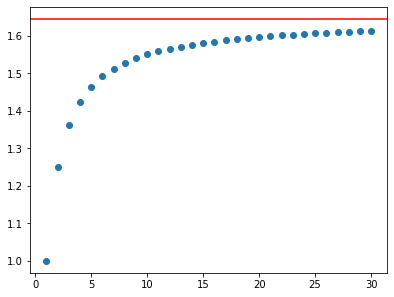

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
s = [N(summation(1 / k**2, (k, 1, m))) for m in range(1, 31)]
plt.plot(range(1, 31), s, 'o')
plt.axhline(N(pi**2 / 6), color='red')
plt.show()
```

</details>

#### Aufgabe 5.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(summation(1, (k, 1, 10)))
display(summation(k, (k, 1, 10)))
summation(Rational(1, 2)**k, (k, 1, oo))
```

In [ ]:
display(summation(1, (k, 1, 10)))
display(summation(k, (k, 1, 10)))
summation(Rational(1, 2)**k, (k, 1, oo))

## 6. Taylorpolynome (Zusatz)

#### Funktionen durch Polynome annähern

Das **Taylorpolynom** vom Grad m einer Funktion an der Stelle 0 hat dieselben Ableitungen bis zur Ordnung m wie die Funktion:
T(x) = f(0) + f'(0)·x + f''(0)/2!·x² + ... + f⁽ᵐ⁾(0)/m!·xᵐ.

`series(f, x, 0, m + 1)` gibt die Entwicklung bis xᵐ und den Rest O(xᵐ⁺¹), `.removeO()` entfernt den Rest.

In [ ]:
display(series(exp(x), x, 0, 5))
T = series(sin(x), x, 0, 8).removeO()
display(T)
plot(sin(x), T, (x, -5, 5), ylim=(-2, 2), legend=True);

#### Aufgabe 6.1

Gib das Taylorpolynom 4. Grades von cos(x) an der Stelle 0 aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{x^{4}}{24} - \frac{x^{2}}{2} + 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
series(cos(x), x, 0, 5).removeO()
```

</details>

#### Aufgabe 6.2

Gib das Taylorpolynom 4. Grades von ln(1 + x) an der Stelle 0 aus.

**Erwartete Ausgabe:**

$\displaystyle - \frac{x^{4}}{4} + \frac{x^{3}}{3} - \frac{x^{2}}{2} + x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
series(log(1 + x), x, 0, 5).removeO()
```

</details>

#### Aufgabe 6.3

Berechne das Taylorpolynom 3. Grades von eˣ von Hand mit der Formel (Summe f⁽ʲ⁾(0)/j! · xʲ) und vergleiche mit `series`.

**Erwartete Ausgabe:**

$\displaystyle \frac{x^{3}}{6} + \frac{x^{2}}{2} + x + 1$

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
T = sum([diff(exp(x), x, j).subs(x, 0) / factorial(j) * x**j for j in range(4)])
display(T)
T == series(exp(x), x, 0, 4).removeO()
```

</details>

#### Aufgabe 6.4

Wie gut nähert das Taylorpolynom 6. Grades von eˣ die Zahl e an? Setze x = 1 ein und gib den Fehler e − T(1) mit 3 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{1957}{720}$

$\displaystyle 0.000226$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
T = series(exp(x), x, 0, 7).removeO()
display(T.subs(x, 1))
N(E - T.subs(x, 1), 3)
```

</details>

#### Aufgabe 6.5

Zeichne cos(x) und seine Taylorpolynome vom Grad 2, 4 und 6 für −5 ≤ x ≤ 5 (y von −2 bis 2, mit Legende).

**Erwartete Ausgabe:**



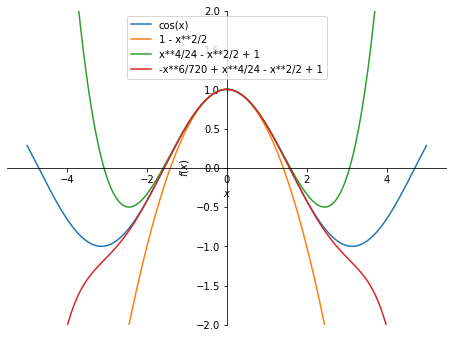

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(cos(x), *[series(cos(x), x, 0, m + 1).removeO() for m in [2, 4, 6]], (x, -5, 5), ylim=(-2, 2), legend=True);
```

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

**Zinseszins:** 1000 € werden mit 4 % pro Jahr verzinst. Gib das Kapital nach 25 Jahren (auf Cent gerundet) und die Formel für das Kapital nach n Jahren aus (geometrische Folge).

**Erwartete Ausgabe:**

$\displaystyle 2665.84$

$\displaystyle 1000 \left(\frac{26}{25}\right)^{n}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Kn = 1000 * Rational(104, 100)**n
display(round(N(Kn.subs(n, 25)), 2))
Kn
```

</details>

#### Aufgabe 7.2

**Sparplan:** Am Anfang jedes Jahres werden 500 € eingezahlt, Zins 3 %. Das Kapital nach n Jahren ist Σₖ₌₁ⁿ 500 · qᵏ mit q = 1,03.
Nach der Summenformel der geometrischen Reihe ist das 500 · q · (qⁿ − 1)/(q − 1). Gib diese Formel und den Wert nach 10 Jahren (auf Cent) aus und vergleiche mit `summation`.

**Erwartete Ausgabe:**

$\displaystyle \frac{51500 \left(\frac{103}{100}\right)^{n}}{3} - \frac{51500}{3}$

$\displaystyle 5903.9$

$\displaystyle 5903.9$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
q = Rational(103, 100)
Kn = 500 * q * (q**n - 1) / (q - 1)
display(Kn)
display(round(N(Kn.subs(n, 10)), 2))
round(N(summation(500 * q**k, (k, 1, 10))), 2)
```

</details>

#### Aufgabe 7.3

Ein Ball fällt aus 2 m Höhe und springt jedes Mal auf 60 % der vorigen Höhe zurück. Wie lang ist der gesamte Weg (nach unten und oben)? 2 + 2 · Σₖ₌₁^∞ 2 · 0,6ᵏ.

**Erwartete Ausgabe:**

$\displaystyle 8$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
2 + 2 * summation(2 * Rational(6, 10)**k, (k, 1, oo))
```

</details>

#### Aufgabe 7.4

**Koch-Schneeflocke:** Der Umfang wächst mit jedem Schritt um den Faktor 4/3 (Startumfang 3), die Fläche ist A = √3/4 · (1 + Σₖ₌₁^∞ 3 · 4ᵏ⁻¹ / 9ᵏ). Gib den Grenzwert des Umfangs
(3 · (4/3)ⁿ für n → ∞) und den Flächeninhalt aus.

**Erwartete Ausgabe:**

$\displaystyle \infty$

$\displaystyle \frac{2 \sqrt{3}}{5}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit(3 * Rational(4, 3)**n, n, oo))
simplify(sqrt(3) / 4 * (1 + summation(3 * 4**(k - 1) / 9**k, (k, 1, oo))))
```

</details>